# Discrimination decay, leakage, broken monotonicity and concentration

**Question:** How large a loss of discrimination, how strong a leak, how broken a monotonicity and how concentrated a rating distribution do the validation tests detect, and how often?

- **Level:** 2, The method in practice
- **Prerequisites:** notebooks 01 to 03 of this topic (the rate, the size of every test, the power ladder)
- **Reading time:** about 60 minutes

## Objectives

By the end of this notebook you can:

- measure the power of the ECB test of the AUC against its initial value and of DeLong's test along a ladder of AUC drops, and read the drop that each catches with 80% power;
- show that an AUC test which treats the development AUC as a known number rejects too often when that AUC is estimated;
- relate a leak to the exact AUC inflation it causes and to the power of the AUC test and of the characteristic stability index (CSI);
- plant a break of monotonicity in a migration matrix, run the migration z-tests and read their power by size of the break and by sample;
- evaluate the ECB concentration statistic over every redistribution of the grades and see that it cannot reach its critical value.

## Setup

Install the pinned environment once, in a virtual environment, with the familiar command:

```bash
pip install -r notebooks/requirements.txt
```

or only the packages this notebook uses, with the same exact pins:

```bash
pip install riskvalidation==1.1.0 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows) builds `.venv-notebooks` for you. The next cell imports the packages and prints their versions.

In [1]:
# Import the tools and print the versions they run with, to compare them with notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from scipy import stats

for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))

riskvalidation 1.0.1
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Data

The data are four families of case C22, validating the validator, each planting one defect of known severity in data drawn from a known-truth generator of `riskvalidation.generators` (licence MIT, class `generated`): `discrimination-decay` lowers the current AUC from the development value of 0.80, with 150 defaulters among 5,000 obligors; `leakage` adds a feature that separates defaulters in development and not at decision time; `broken-monotonicity` raises one cell of a seven-grade migration matrix above its closer neighbour; `concentration` moves a share of every grade into the modal grade of ten grades.

- **Files read:** `data/derived/C22/discrimination-decay.json`, `leakage.json`, `broken-monotonicity.json` and `concentration.json`, keys `outputs` and `provenance`.
- **What is taken from them:** the ladders, and the generator configuration and seed of each rung, from which the engine draws the datasets again here.

The next cell loads the four files and prints the engine versions.

In [2]:
# Load the four families of defects and index their simulations by family and key
LANG = "en"
ROOT = Path("../../..").resolve()
names = ("discrimination-decay", "leakage", "broken-monotonicity", "concentration")
families = {n: json.loads((ROOT / "data" / "derived" / "C22" / f"{n}.json").read_text(encoding="utf-8")) for n in names}
rows = {n: {row["key"]: row for row in fam["outputs"]["simulations"]} for n, fam in families.items()}
for n in names:
    version = families[n]["provenance"]["riskvalidation_version"]
    print(f"{n:22s} {len(rows[n]):2d} simulations | baked by {version} | installed {rv.__version__}")

discrimination-decay   21 simulations | baked by 1.0.1 | installed 1.0.1
leakage                14 simulations | baked by 1.0.1 | installed 1.0.1
broken-monotonicity    24 simulations | baked by 1.0.1 | installed 1.0.1
concentration          12 simulations | baked by 1.0.1 | installed 1.0.1


## Method

**The ECB AUC test.** With $\mathrm{AUC}_\text{init}$ the development AUC and $\mathrm{AUC}_\text{curr}$ the current one, the ECB treats the development value as a known number and tests

$$S = \frac{\mathrm{AUC}_\text{init} - \mathrm{AUC}_\text{curr}}{s},$$

with $s$ the standard error of the current AUC. DeLong's test compares two AUCs measured on the same sample through their correlated standard errors. **The migration z-tests** compare each cell of a migration matrix with its neighbours and adjust the p-values for the number of cells. **The concentration test** looks at the coefficient of variation of the grade frequencies. For each defect, a ladder of severity is run through the engine with `simulate` and the rejection rate at 5% is the power; the rung with no defect is the size.

### Part A, step 1: how large an AUC drop is caught

The `discrimination-decay` family lowers the current AUC from 0.80 by 0 to 0.08 with 150 defaulters. The next cell simulates the ECB test and DeLong's test on each rung, 500 repetitions each, prints the power along the ladder and the drop at which each crosses 80% by linear interpolation, and draws both curves.

AUC drops of the ladder: [0.0, 0.01, 0.02, 0.03, 0.05, 0.08]
disc.auc_vs_initial  [0.022, 0.11, 0.26, 0.478, 0.8, 0.986] | drop at 80% power 0.05
disc.delong          [0.044, 0.076, 0.194, 0.358, 0.704, 0.966] | drop at 80% power 0.061


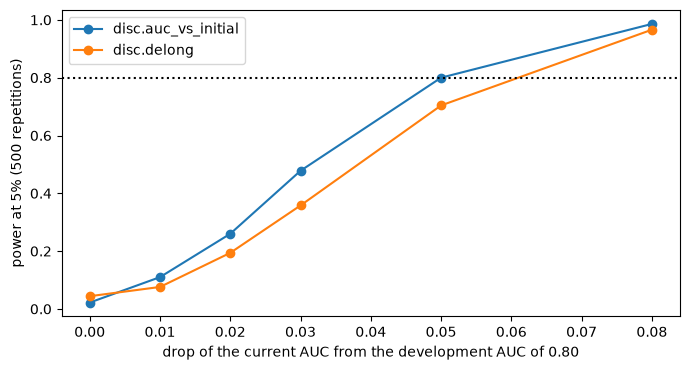

In [3]:
# Simulate the ECB AUC test and DeLong along the ladder of AUC drops
from riskvalidation.generators.scores import BinormalScores
from riskvalidation.harness.run import simulate

decay = families["discrimination-decay"]["outputs"]
drops = decay["ladder"]["values"]
power = {"disc.auc_vs_initial": [], "disc.delong": []}
for drop in drops:
    for test in power:
        row = rows["discrimination-decay"][f"{test}@d{drop:g}"]
        generator = BinormalScores(**decay["generators"][row["generator"]]["config"])
        power[test].append(simulate(test, generator, n_rep=500, seed=row["seed"]).rates["p<0.05"].rate)
fig, ax = plt.subplots(figsize=(7, 3.8))
print("AUC drops of the ladder:", drops)
for test, values in power.items():
    ax.plot(drops, values, "o-", label=test)
    caught = float(np.interp(0.8, np.maximum.accumulate(values), drops))
    print(f"{test:20s}", [round(v, 3) for v in values], "| drop at 80% power", round(caught, 4))
ax.axhline(0.8, color="black", linestyle=":")
ax.set_xlabel("drop of the current AUC from the development AUC of 0.80")
ax.set_ylabel("power at 5% (500 repetitions)")
ax.legend()
fig.tight_layout()
plt.show()

On the ladder of drops 0, 0.01, 0.02, 0.03, 0.05 and 0.08, the ECB test has power 0.022, 0.110, 0.260, 0.478, 0.800 and 0.986, so it catches a drop of 5 AUC points four times in five and a drop of 2 points one time in four. DeLong's test is less powerful, with 0.044 to 0.966, and crosses 80% at a drop of 0.061. The ECB test benefits from taking the development AUC as exact: that assumption removes one source of variance, and the next step shows what it costs.

### Part A, step 2: the development AUC is an estimate too

In practice the development AUC was estimated on a development sample and carries its own error, which the ECB form ignores. The generator returns the variance of the development AUC with each draw, and an extended form of the test adds it. The next cell measures the size of the test, with no real drop, with a development sample sixteen times the current one (`m16`), with an equal one (`m1`), and with the extended form at the equal one (`m1-extended`).

In [4]:
# Size of the ECB AUC test when the development AUC is estimated, ECB form and extended
extended = lambda d: {"auc_initial": d["auc_initial"], "risk": d["risk"], "defaults": d["defaults"],
                      "auc_initial_variance": d["development_auc_variance"]}
for tag, feed in (("m16", None), ("m1", None), ("m1-extended", extended)):
    row = rows["discrimination-decay"][f"disc.auc_vs_initial@{tag}"]
    generator = BinormalScores(**decay["generators"][row["generator"]]["config"])
    run = simulate("disc.auc_vs_initial", generator, n_rep=1000, seed=row["seed"], feed=feed)
    measured = run.rates["p<0.05"]
    print(f"{tag:12s} | current over development sample {row['x']:.3f}", end=" | ")
    print(f"size at 5% {measured.rate:.4f}")

m16          | current over development sample 0.062 | size at 5% 0.0470
m1           | current over development sample 1.000 | size at 5% 0.1270
m1-extended  | current over development sample 1.000 | size at 5% 0.0590


With a development sample sixteen times larger than the current one the size is 0.0470, close to its level, because the development AUC is then nearly exact and the ECB assumption costs little. With equal samples the ECB form rejects a right model 0.1270 of the time at a nominal 5%, and the extended form that adds the development variance brings it back to 0.0590. The ECB form is exact only when the development AUC is known; with equal samples it more than doubles its level.

### Part B, step 3: what a leak does to the tests

In the `leakage` family a feature shifts for defaulters by the leak $\lambda$ in development and not at decision time, so the model's AUC is inflated in development and falls when the leak disappears. The generator's `truth()` gives both AUCs exactly. The next cell computes the AUC inflation of each rung, simulates the AUC test and the CSI on it, 500 repetitions each, and draws the inflation and the two power curves.

leak 0.00 | AUC inflation 0.0000 | AUC test 0.044 | CSI 0.040
leak 0.25 | AUC inflation 0.0426 | AUC test 0.642 | CSI 0.064
leak 0.50 | AUC inflation 0.0819 | AUC test 0.980 | CSI 0.074
leak 1.00 | AUC inflation 0.1499 | AUC test 1.000 | CSI 0.138
leak 1.50 | AUC inflation 0.2029 | AUC test 1.000 | CSI 0.338
leak 2.00 | AUC inflation 0.2417 | AUC test 1.000 | CSI 0.564


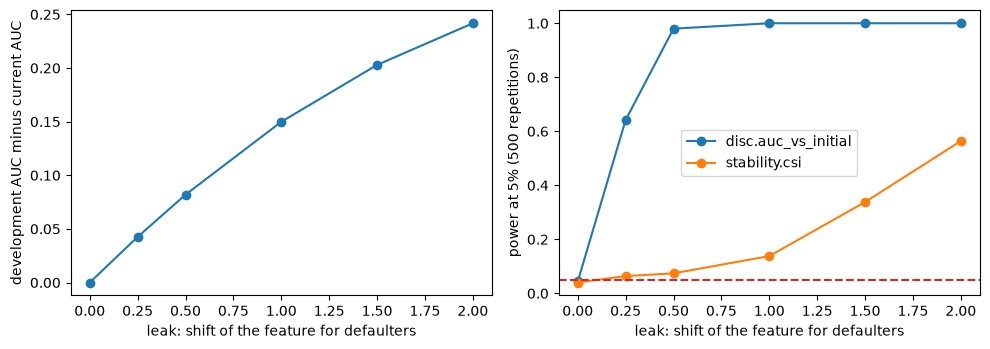

In [5]:
# Exact AUC inflation of each leak and power of the AUC test and the CSI along the ladder
leak = families["leakage"]["outputs"]
leaks = leak["ladder"]["values"]
inflation, hits = [], {"disc.auc_vs_initial": [], "stability.csi": []}
for lam in leaks:
    for test in hits:
        row = rows["leakage"][f"{test}@l{lam:g}"]
        generator = BinormalScores(**leak["generators"][row["generator"]]["config"])
        hits[test].append(simulate(test, generator, n_rep=500, seed=row["seed"]).rates["p<0.05"].rate)
    truth = generator.truth()
    inflation.append(truth["auc_development"] - truth["auc_current"])
    print(f"leak {lam:4.2f} | AUC inflation {inflation[-1]:.4f}", end=" | ")
    print(f"AUC test {hits['disc.auc_vs_initial'][-1]:.3f} | CSI {hits['stability.csi'][-1]:.3f}")
fig, (left, right) = plt.subplots(1, 2, figsize=(10, 3.6))
left.plot(leaks, inflation, "o-")
left.set_xlabel("leak: shift of the feature for defaulters")
left.set_ylabel("development AUC minus current AUC")
for test, values in hits.items():
    right.plot(leaks, values, "o-", label=test)
right.axhline(0.05, color="tab:red", linestyle="--")
right.set_xlabel("leak: shift of the feature for defaulters")
right.set_ylabel("power at 5% (500 repetitions)")
right.legend()
fig.tight_layout()
plt.show()

A leak of 1.0 inflates the development AUC by 0.1499, and a leak of 2.0 by 0.2417. The AUC test notices it early: its power is 0.642 at a leak of 0.25, which inflates the AUC by 0.0426, and 0.980 at 0.50. The CSI, which watches the leaking feature itself, is much slower, with 0.064 at 0.25 and 0.564 only at a leak of 2.0. When the leak is the cause of the drop, the AUC sees the effect long before the stability index sees the feature that caused it, and in practice a validator should read the two together.

### Part C, step 4: the planted break of monotonicity

A migration matrix should not have a cell two notches from the diagonal that is more frequent than its closer neighbour. The generator takes a decaying seven-grade matrix with `decaying_matrix` and `break_monotonicity` sets one cell, from grade 4 to grade 2, to a multiple of its neighbour. The next cell builds the base matrix and the planted one with a ratio of 2, prints row 4 of both and draws them side by side.

row of grade 4, base:    [0.0143 0.0286 0.0571 0.8    0.0571 0.0286 0.0143]
row of grade 4, planted: [0.0143 0.1143 0.0571 0.7143 0.0571 0.0286 0.0143]
cell 4 to 2 over its neighbour 4 to 3: 2.0


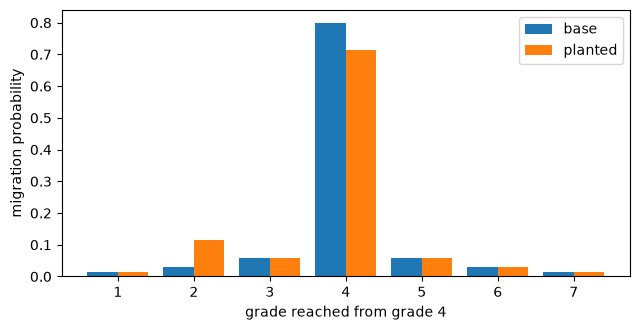

In [6]:
# Build the base matrix and the one with a planted break of monotonicity, draw row 4
from riskvalidation.generators.ratings import break_monotonicity, decaying_matrix
from riskvalidation.validation.rating_system import rating_migration_ztests

base = decaying_matrix(7)
planted = break_monotonicity(base, 3, 1, 2.0)
print("row of grade 4, base:   ", np.round(base[3], 4))
print("row of grade 4, planted:", np.round(planted[3], 4))
print("cell 4 to 2 over its neighbour 4 to 3:", round(float(planted[3, 1] / planted[3, 2]), 3))
fig, ax = plt.subplots(figsize=(6.5, 3.4))
grades = np.arange(1, 8)
ax.bar(grades - 0.2, base[3], width=0.4, label="base")
ax.bar(grades + 0.2, planted[3], width=0.4, label="planted")
ax.set_xlabel("grade reached from grade 4")
ax.set_ylabel("migration probability")
ax.legend()
fig.tight_layout()
plt.show()

In the base matrix the row of grade 4 is 0.0143, 0.0286, 0.0571, 0.8000, 0.0571, 0.0286 and 0.0143: the probability falls steadily as the distance from the diagonal grows. In the planted one the entry for grade 2 is 0.1143, twice the 0.0571 of grade 3, a ratio of 2.0 printed by the cell, and the diagonal gives up the mass, 0.7143. The picture shows a single bar sticking out of an otherwise monotone row, and that is the defect the z-tests have to find.

### Part C, step 5: the z-tests on one sample, and their power

The next cell draws 500 obligors per grade from the planted matrix, runs `rating_migration_ztests` and prints the number of cells with a raw p-value below 5%, the smallest Holm-adjusted p-value and the worst cell. It then simulates the test over the ladder of ratios with 500 and 2,000 obligors per grade, 300 repetitions per rung, and draws the power curves.

cells with a raw p below 5%: 1 | smallest adjusted p: 4.06e-04
worst cell: grade 4 to grade 2
ratios of the ladder: [1.0, 1.25, 1.5, 2.0, 3.0, 4.0]
  500 obligors per grade: [0.0, 0.007, 0.05, 0.54, 0.997, 1.0]
 2000 obligors per grade: [0.003, 0.08, 0.607, 1.0, 1.0, 1.0]


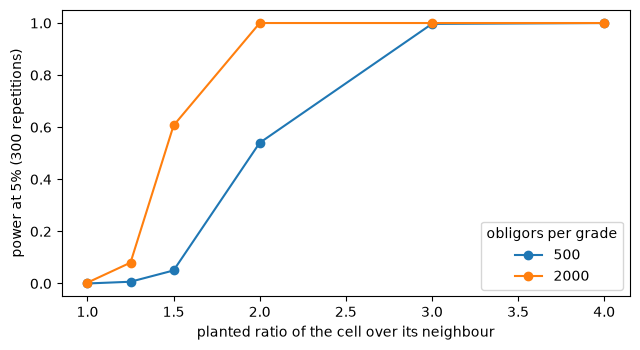

In [7]:
# Run the migration z-tests on one sample and measure their power by ratio and size
from riskvalidation.generators.ratings import Migrations

mono = families["broken-monotonicity"]["outputs"]
ratios = mono["ladder"]["values"]
row = rows["broken-monotonicity"]["rating.migration_ztests@r2-n500"]
migrations = Migrations(**mono["generators"][row["generator"]]["config"])
result = rating_migration_ztests(migrations.draw(np.random.default_rng(3))["counts"])
worst = min(result.extras["cells"], key=lambda cell: cell["p_holm"])
print("cells with a raw p below 5%:", int(result.statistic), "| smallest adjusted p:", f"{result.p_value:.2e}")
print("worst cell: grade", worst["from"], "to grade", worst["to"])
print("ratios of the ladder:", ratios)
fig, ax = plt.subplots(figsize=(6.5, 3.6))
for n_obs in (500, 2000):
    rates = []
    for ratio in ratios:
        item = rows["broken-monotonicity"][f"rating.migration_ztests@r{ratio:g}-n{n_obs}"]
        generator = Migrations(**mono["generators"][item["generator"]]["config"])
        rates.append(simulate(item["test_id"], generator, n_rep=300, seed=item["seed"]).rates["p<0.05"].rate)
    ax.plot(ratios, rates, "o-", label=f"{n_obs}")
    print(f"{n_obs:5d} obligors per grade:", [round(r, 3) for r in rates])
ax.set_xlabel("planted ratio of the cell over its neighbour")
ax.set_ylabel("power at 5% (300 repetitions)")
ax.legend(title="obligors per grade")
fig.tight_layout()
plt.show()

On the one sample drawn only 1 cell has a raw p-value below 5%, the worst is the cell from grade 4 to grade 2, and its adjusted p-value is 4.06e-04, enough to reject at 5%. Along the ladder of ratios 1, 1.25, 1.5, 2, 3 and 4, with 500 obligors per grade the power is 0.000, 0.007, 0.050, 0.540, 0.997 and 1.000, and with 2,000 it is 0.003, 0.080, 0.607, 1.000, 1.000 and 1.000. A cell twice its neighbour is caught more than half the time with 500 obligors, and a break of 1.5 needs 2,000 obligors to reach 0.607.

### Part D, step 6: a bounded statistic

The `concentration` family moves a share of every grade's mass into the modal grade of ten grades. The statistic of the ECB concentration test depends only on the frequencies, through their coefficient of variation, and it is compared with a normal critical value. The next cell evaluates `rating_hhi` over 201 shares moved, from 0 to 1, finds the largest statistic and sets it against the critical value at 5%, and draws the statistic as a function of the share.

coefficient of variation of the development frequencies: 0.6017
largest statistic: 1.0913 at the share 0.375
critical value at 5%: 1.6449


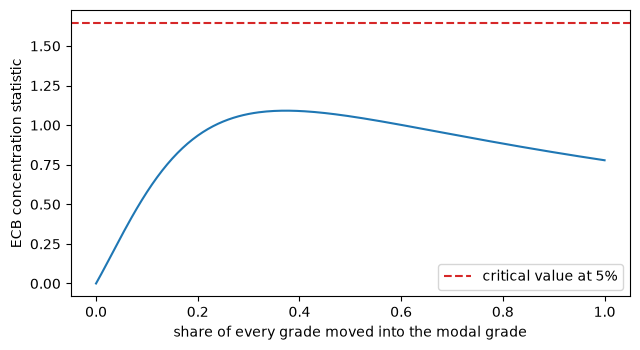

In [8]:
# Evaluate the ECB concentration statistic over every share moved into the modal grade
from riskvalidation.generators.ratings import concentrate
from riskvalidation.validation.rating_system import concentration, rating_hhi

conc = families["concentration"]["outputs"]
initial = np.array(conc["generators"]["grades-10-c0.5"]["config"]["initial"])
cv_initial, hi_initial = concentration(initial)
shares = np.linspace(0.0, 1.0, 201)
statistics = np.array([rating_hhi(concentrate(initial, s), initial).statistic for s in shares])
best = int(np.argmax(statistics))
print("coefficient of variation of the development frequencies:", round(cv_initial, 4))
print("largest statistic:", round(float(statistics[best]), 4), "at the share", shares[best])
print("critical value at 5%:", round(float(stats.norm.isf(0.05)), 4))
fig, ax = plt.subplots(figsize=(6.5, 3.6))
ax.plot(shares, statistics)
ax.axhline(stats.norm.isf(0.05), color="tab:red", linestyle="--", label="critical value at 5%")
ax.set_xlabel("share of every grade moved into the modal grade")
ax.set_ylabel("ECB concentration statistic")
ax.legend()
fig.tight_layout()
plt.show()

The development frequencies have a coefficient of variation of 0.6017, and as the share moved grows the statistic rises, peaks at 1.0913 for a share of 0.375 and then falls as the distribution collapses into one grade, where the coefficient of variation is bounded. The critical value at 5% is 1.6449, so no redistribution of these ten grades, however extreme, can make the test reject. A test whose statistic cannot reach its threshold has a power of zero by construction, whatever the data.

### Part D, step 7: the power of the concentration test and of the chi-square

The next cell simulates the ECB concentration test and the chi-square test of homogeneity along the ladder of shares moved, 500 repetitions per rung, and draws the two curves. The chi-square test compares the whole distribution of grades with the development one, so it is a natural contrast.

shares of the ladder: [0.0, 0.01, 0.02, 0.05, 0.1, 0.5]
rating.hhi       [0.0, 0.0, 0.0, 0.0, 0.0, 0.0]
stability.chi2   [0.056, 0.082, 0.226, 0.956, 1.0, 1.0]


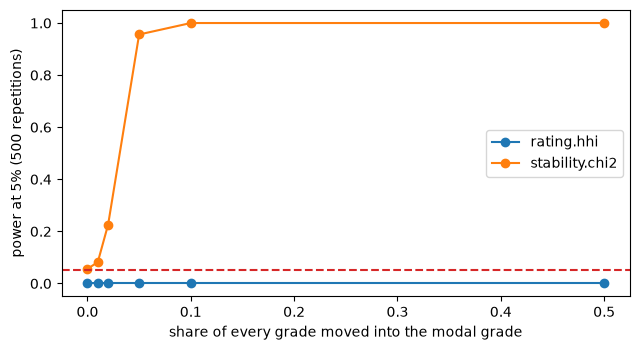

In [9]:
# Measure the power of the concentration test and of the chi-square along the share moved
from riskvalidation.generators.ratings import GradeFrequencies

moved = conc["ladder"]["values"]
print("shares of the ladder:", moved)
fig, ax = plt.subplots(figsize=(6.5, 3.6))
for test in ("rating.hhi", "stability.chi2"):
    rates = []
    for share in moved:
        item = rows["concentration"][f"{test}@c{share:g}"]
        generator = GradeFrequencies(**conc["generators"][item["generator"]]["config"])
        rates.append(simulate(test, generator, n_rep=500, seed=item["seed"]).rates["p<0.05"].rate)
    ax.plot(moved, rates, "o-", label=test)
    print(f"{test:16s}", [round(r, 3) for r in rates])
ax.axhline(0.05, color="tab:red", linestyle="--")
ax.set_xlabel("share of every grade moved into the modal grade")
ax.set_ylabel("power at 5% (500 repetitions)")
ax.legend()
fig.tight_layout()
plt.show()

The concentration test has a power of 0.000 on every rung, from no shift to half the mass of each grade moved into the modal one, exactly as the bounded statistic predicted. The chi-square test, on the same data, goes from 0.056 with no shift to 0.082 for a share of 0.01, 0.226 for 0.02, 0.956 for 0.05 and 1.000 for 0.10 and 0.50. The two tests look at different things, but only one of them can see a distribution that is collapsing, and a validator who relies on the concentration test alone would never be warned.

## Results

**Answer:** With 150 defaulters, the ECB test catches a drop of 5 AUC points with 0.800 power and DeLong's test needs a drop of 0.061; a drop of 2 points is caught only 0.260 of the time. A leak of 0.25 inflates the development AUC by 0.0426 and the AUC test detects it with 0.642 power while the CSI reaches 0.064. A migration cell twice its neighbour is caught 0.540 of the time with 500 obligors per grade and always with 2,000. The ECB concentration test cannot reject at all: its largest statistic is 1.0913 against a critical value of 1.6449, while the chi-square test reaches 0.956 when 5% of the mass is moved.

- **The ECB form of the AUC test is anti-conservative with an estimated development AUC.** With equal samples its size is 0.1270, and 0.0590 with the extended form.
- **The effect appears before the cause.** The AUC test sees a leak at 0.25 where the CSI of the leaking feature has 0.064.
- **A bounded statistic is a test that cannot work.** The concentration test's power is 0.000 on every rung.

The tests of the other families, and the exact rejection probabilities, are in the previous notebooks of the topic.

## Summary

- The ECB AUC test catches a drop of 5 AUC points on 150 defaulters with power 0.800, and DeLong's test a drop of 6 points; a drop of 2 points goes unseen three times in four.
- The ECB form treats the development AUC as a known number, and with equal samples that raises its size to 0.1270; adding the development variance restores it.
- A leak shows in the AUC test far sooner than in the CSI of the leaking feature.
- The migration z-tests catch a cell twice its neighbour half the time with 500 obligors per grade and always with 2,000.
- The ECB concentration statistic is bounded below its critical value for these ten grades, so the test has power zero.

**What to try next.** Rerun step 6 with the grade frequencies of a portfolio of four grades and see whether the bound changes, then read notebook 07.

## References

- ECB (2019), Instructions for reporting the validation results of internal models: IRB Pillar I models for credit risk, sections 2.5.4.1, 2.5.5.2 and 2.5.5.3 and Annex 3.1 (the AUC against the initial AUC, the migration z-tests, the concentration test). https://www.bankingsupervision.europa.eu/activities/internal_models/shared/pdf/instructions_validation_reporting_credit_risk.en.pdf
- Hanley, J. A. and McNeil, B. J. (1982), The meaning and use of the area under a receiver operating characteristic curve, Radiology 143(1). https://doi.org/10.1148/radiology.143.1.7063747
- Demler, O. V., Pencina, M. J. and D'Agostino, R. B. Sr (2012), Misuse of DeLong test to compare AUCs for nested models, Statistics in Medicine 31(23). https://doi.org/10.1002/sim.5328
- Tasche, D. (2013), The art of probability-of-default curve calibration, Journal of Credit Risk 9(4): the default-profile test. https://doi.org/10.21314/jcr.2013.169
- Morris, T. P., White, I. R. and Crowther, M. J. (2019), Using simulation studies to evaluate statistical methods, Statistics in Medicine 38(11). https://doi.org/10.1002/sim.8086
- This repository: `docs/design/features/c22-validator/requirements.md` and `data-pipeline/pipeline/cases/c22_validator.py`, which wrote the artifacts.